# Imports

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

## Helper functions

In [2]:
def describe_raw_data(df: pd.DataFrame) -> pd.DataFrame:
    
    data_types_1 = {}

    for column, datatype in df.dtypes.items():
        datatype_name = datatype.name
        
        if "column" not in data_types_1:
            data_types_1["column"] = []
        
        data_types_1["column"].append(column)
        
        if "data_type" not in data_types_1:
            data_types_1["data_type"] = []
        
        data_types_1["data_type"].append(datatype_name)
        
    df_datatypes_1 = pd.DataFrame(data_types_1)
    
    data = {
        "unique_values_preview": [],
        "num_unique_values": [],
        "num_NaN_values": []
    }

    for column in df_datatypes_1["column"]:
        num_unique_values = df[column].nunique()
        data["num_unique_values"].append(num_unique_values)
        
        if num_unique_values > 3:
            unique_values = ", ".join([str(value) for value in df[column].dropna().unique()[:3]]) + ", ..."
        else:
            unique_values = ", ".join(str(value) for value in df[column].dropna().unique())
            
        data["unique_values_preview"].append(unique_values)
        
        data["num_NaN_values"].append(df[column].isnull().sum())

    df_datatypes_concat = pd.concat([df_datatypes_1, pd.DataFrame(data)], axis=1).sort_values(["data_type", "num_unique_values"]).set_index("data_type")

    return df_datatypes_concat

In [3]:
def comparison_countplot_charts(orig_df: pd.DataFrame, df1: pd.DataFrame, df2: pd.DataFrame, column: str):
    fig, axes = plt.subplots(1, 2, figsize=(10, 6))

    order = orig_df[column].value_counts().keys().to_list()
    
    sns.countplot(df1, x=column, order=order, ax=axes[0], color="red")
    sns.countplot(df2, x=column, order=order, ax=axes[1])

    axes[0].set_title("Fraud: Yes")
    axes[1].set_title("Fraud: No")

In [19]:
def comparison_pie_chart(df1: pd.DataFrame, df2: pd.DataFrame, main_column: str):
    
    fraud_card_type_labels = df1.drop_duplicates("card_id")[main_column].value_counts().keys()
    fraud_card_type_values = df1.drop_duplicates("card_id")[main_column].value_counts().values

    not_fraud_card_type_labels = df2.drop_duplicates("card_id")[main_column].value_counts().keys()
    not_fraud_card_type_values = df2.drop_duplicates("card_id")[main_column].value_counts().values

    fig, (ax1, ax2) = plt.subplots(1, 2)

    fig.set_figwidth(12)
    fig.set_figheight(8)

    ax1.pie(not_fraud_card_type_values, labels=not_fraud_card_type_labels, autopct='%.1f%%')
    ax1.set_title("Not Fraud")

    ax2.pie(fraud_card_type_values, labels=fraud_card_type_labels, autopct='%.1f%%')
    ax2.set_title("Fraud")

    plt.show()

## Data imports

In [4]:
# CSV imports
cards = pd.read_csv("project_data/cards_data.csv").rename(columns={"id": "card_id"})
users = pd.read_csv("project_data/users_data.csv").rename(columns={"id": "client_id"})
transactions = pd.read_csv("project_data/transactions_data.csv").rename(columns={"id": "transaction_id"})

# JSON imports
series_mcc_codes = pd.read_json("project_data/mcc_codes.json", typ="series")
series_mcc_codes.name = "mcc_code_description"
mcc_codes = pd.DataFrame(series_mcc_codes).reset_index().rename(columns={"index": "mcc_code"})

train_labels = pd.read_json("project_data/train_fraud_labels.json").reset_index().rename(columns={"index": "transaction_id"})

In [5]:
df = transactions \
    .merge(train_labels, on="transaction_id", how="left") \
        .merge(cards.merge(users, on="client_id", how="left"), on="card_id", how="left") \
            .drop("client_id_y", axis=1) \
                .rename(columns={"mcc": "mcc_code", "client_id_x": "client_id"}) \
                    .merge(mcc_codes, on="mcc_code", how="left")

In [6]:
describe_raw_data(df)

,column,unique_values_preview,num_unique_values,num_NaN_values
data_type,,,,
float64,latitude,"46.8, 40.8, 33.18, ...",740,0
float64,longitude,"-100.76, -91.12, -117.29, ...",859,0
float64,zip,"58523.0, 52722.0, 92084.0, ...",25256,1652706
int64,num_cards_issued,"2, 1, 3",3,0
int64,num_credit_cards,"4, 5, 3, ...",9,0
int64,birth_month,"7, 6, 4, ...",12,0
int64,year_pin_last_changed,"2008, 2015, 2006, ...",19,0
int64,retirement_age,"67, 65, 69, ...",27,0
int64,current_age,"30, 48, 49, ...",74,0


# Data Cleaning

In [7]:
df = df.drop(["errors", "card_on_dark_web"], axis=1).drop_duplicates()

In [8]:
columns_to_clean = ["per_capita_income", "total_debt", "yearly_income", "credit_limit", "amount"]

for column in columns_to_clean:
    df[column] = df[column].str.replace("$", "").astype("float64")
    
df["date"] = pd.to_datetime(df["date"])

In [9]:
test_set = df[df["target"].isnull()]
df = df.drop(test_set.index)

In [10]:
len(test_set), len(df)

(4390952, 8914963)

In [11]:
describe_raw_data(df)

,column,unique_values_preview,num_unique_values,num_NaN_values
data_type,,,,
datetime64[us],date,"2010-01-01 00:01:00, 2010-01-01 00:02:00, 2010...",3680988,0
float64,latitude,"46.8, 40.8, 33.18, ...",740,0
float64,longitude,"-100.76, -91.12, -117.29, ...",859,0
float64,per_capita_income,"23679.0, 18076.0, 16894.0, ...",1120,0
float64,total_debt,"110153.0, 112139.0, 36540.0, ...",1150,0
float64,yearly_income,"48277.0, 36853.0, 34449.0, ...",1201,0
float64,credit_limit,"55.0, 9100.0, 14802.0, ...",2603,0
float64,zip,"58523.0, 52722.0, 92084.0, ...",24586,1107377
float64,amount,"-77.0, 14.57, 80.0, ...",70638,0


In [12]:
describe_raw_data(test_set)

,column,unique_values_preview,num_unique_values,num_NaN_values
data_type,,,,
datetime64[us],date,"2010-01-01 00:05:00, 2010-01-01 00:09:00, 2010...",2662429,0
float64,latitude,"41.42, 46.8, 26.74, ...",740,0
float64,longitude,"-87.35, -100.76, -80.12, ...",859,0
float64,per_capita_income,"26168.0, 23679.0, 27696.0, ...",1120,0
float64,total_debt,"128676.0, 110153.0, 66565.0, ...",1150,0
float64,yearly_income,"53350.0, 48277.0, 56467.0, ...",1201,0
float64,credit_limit,"37634.0, 55.0, 23401.0, ...",2603,0
float64,zip,"46307.0, 58523.0, 11355.0, ...",23015,545329
float64,amount,"200.0, 77.0, 261.58, ...",55323,0


# Exploratory Data Analysis

Interestingly, when indexes where their zip codes are null are removed, the number of Fraud records are reduced by a significant margin. They have been added back in to analyze what limited Fraud data we have.

In [13]:
target_yes = df[df["target"] == "Yes"]
target_no = df[df["target"] == "No"]

## Age by target group

<Axes: xlabel='current_age', ylabel='Density'>

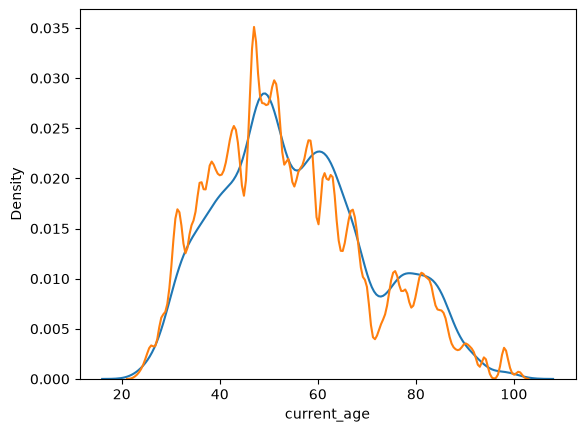

In [14]:
sns.kdeplot(target_yes, x="current_age")
sns.kdeplot(target_no, x="current_age")

## Card type by target group

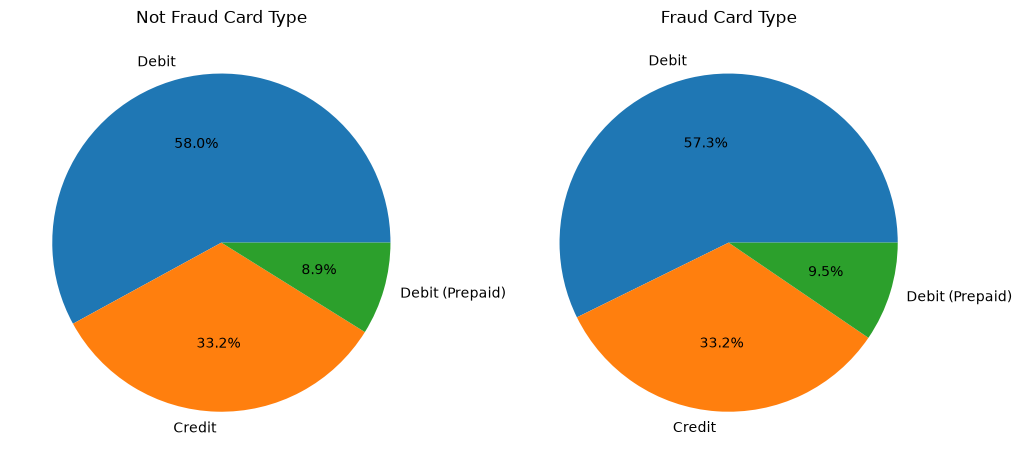

In [26]:
fraud_card_type_labels = target_yes.drop_duplicates("card_id")["card_type"].value_counts().keys()
fraud_card_type_values = target_yes.drop_duplicates("card_id")["card_type"].value_counts().values

not_fraud_card_type_labels = target_no.drop_duplicates("card_id")["card_type"].value_counts().keys()
not_fraud_card_type_values = target_no.drop_duplicates("card_id")["card_type"].value_counts().values

fig, (ax1, ax2) = plt.subplots(1, 2)

fig.set_figwidth(12)
fig.set_figheight(8)

ax1.pie(not_fraud_card_type_values, labels=not_fraud_card_type_labels, autopct='%.1f%%')
ax1.set_title("Not Fraud Card Type")

ax2.pie(fraud_card_type_values, labels=fraud_card_type_labels, autopct='%.1f%%')
ax2.set_title("Fraud Card Type")

plt.show()

## Chip Type by target group

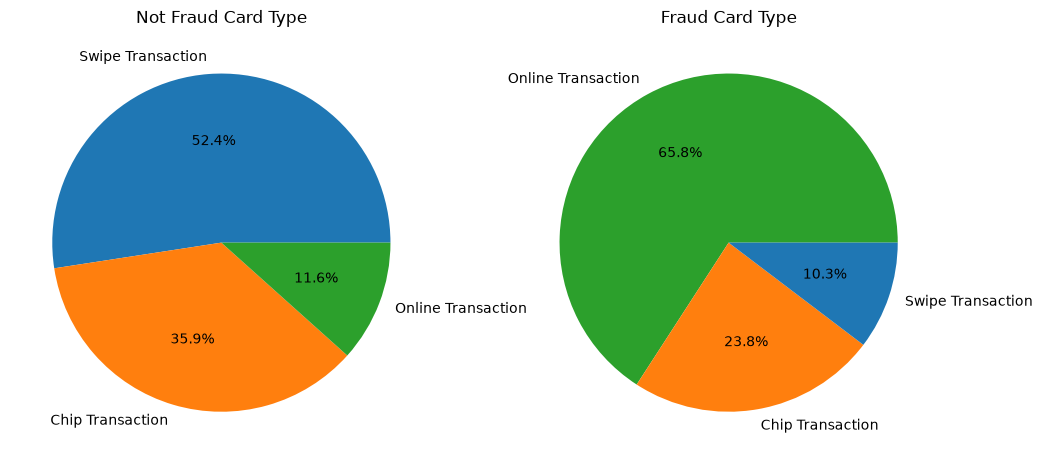

In [25]:
fraud_card_type_labels = target_yes["use_chip"].value_counts().keys()
fraud_card_type_values = target_yes["use_chip"].value_counts().values

not_fraud_card_type_labels = target_no["use_chip"].value_counts().keys()
not_fraud_card_type_values = target_no["use_chip"].value_counts().values

fig, (ax1, ax2) = plt.subplots(1, 2)

fig.set_figwidth(12)
fig.set_figheight(8)

ax1.pie(not_fraud_card_type_values, labels=not_fraud_card_type_labels, autopct='%.1f%%')
ax1.set_title("Not Fraud Card Type")

ax2.pie(fraud_card_type_values, labels=fraud_card_type_labels, autopct='%.1f%%', colors=["tab:green", "tab:orange", "tab:blue"])
ax2.set_title("Fraud Card Type")

plt.show()

## Card Brand by target group

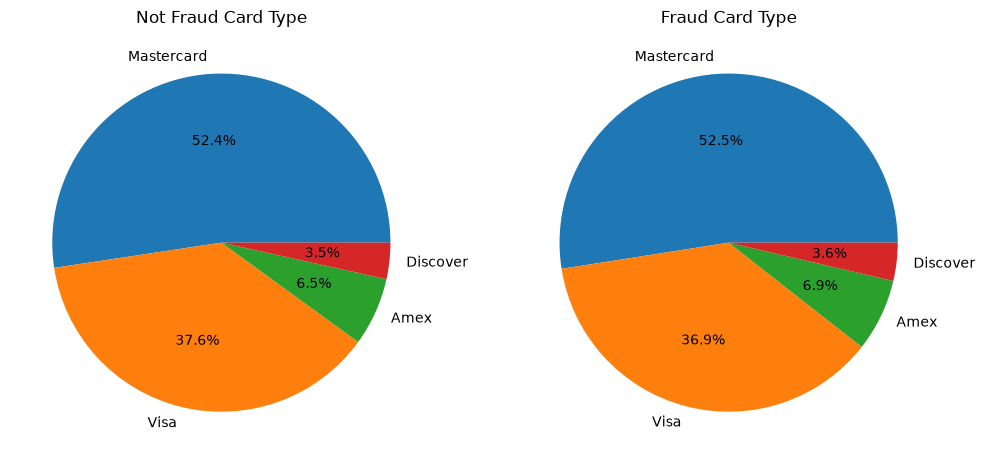

In [27]:
fraud_card_type_labels = target_yes.drop_duplicates("card_id")["card_brand"].value_counts().keys()
fraud_card_type_values = target_yes.drop_duplicates("card_id")["card_brand"].value_counts().values

not_fraud_card_type_labels = target_no.drop_duplicates("card_id")["card_brand"].value_counts().keys()
not_fraud_card_type_values = target_no.drop_duplicates("card_id")["card_brand"].value_counts().values

fig, (ax1, ax2) = plt.subplots(1, 2)

fig.set_figwidth(12)
fig.set_figheight(8)

ax1.pie(not_fraud_card_type_values, labels=not_fraud_card_type_labels, autopct='%.1f%%')
ax1.set_title("Not Fraud Card Type")

ax2.pie(fraud_card_type_values, labels=fraud_card_type_labels, autopct='%.1f%%')
ax2.set_title("Fraud Card Type")

plt.show()